In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.utils import to_categorical

(X_train_raw, y_train_raw), (X_test_raw, y_test_raw) = fashion_mnist.load_data()


X_train_cnn = X_train_raw.astype('float32') / 255.0
X_test_cnn = X_test_raw.astype('float32') / 255.0

X_train_cnn = np.expand_dims(X_train_cnn, -1)
X_test_cnn = np.expand_dims(X_test_cnn, -1)


y_train_cnn = to_categorical(y_train_raw, 10)
y_test_cnn = to_categorical(y_test_raw, 10)

print("Fashion-MNIST Dataset loaded successfully.")
print(f"Training features shape: {X_train_cnn.shape}")
print(f"Test features shape: {X_test_cnn.shape}")

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Fashion-MNIST Dataset loaded successfully.
Training features shape: (60000, 28, 28, 1)
Test features shape: (10000, 28, 28, 1)


### Subtask 1.2: Designing the CNN Architecture

**Concept:** Construct a 2D Convolutional Neural Network using convolution, max-pooling, flattening, dense, and dropout layers for Fashion-MNIST image classification.

In [2]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

# Design sequential CNN
cnn_model = Sequential([

    # First convolution and pooling block
    Conv2D(
        32,
        (3, 3),
        activation='relu',
        input_shape=(28, 28, 1)
    ),
    MaxPooling2D((2, 2)),

    # Second convolution and pooling block
    Conv2D(
        64,
        (3, 3),
        activation='relu'
    ),
    MaxPooling2D((2, 2)),

    # Convert feature maps into vector
    Flatten(),

    # Dense classification layers
    Dense(128, activation='relu'),
    Dropout(0.25),

    # 10 Fashion-MNIST classes
    Dense(10, activation='softmax')
])

print("CNN Architecture successfully established:")
cnn_model.summary()

CNN Architecture successfully established:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

### Subtask 1.3: Compiling the CNN Model

**Concept:** Compile the CNN model using the Adam optimizer, categorical cross-entropy loss, and accuracy as the evaluation metric.

In [3]:
# Compile CNN model
cnn_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("CNN model compiled successfully with Adam optimizer.")

CNN model compiled successfully with Adam optimizer.


### Subtask 1.4: Training the CNN Model

**Concept:** Train the CNN model on the Fashion-MNIST training images using a validation split to monitor model performance during training.

In [4]:
# Train CNN model
history_cnn = cnn_model.fit(
    X_train_cnn,
    y_train_cnn,
    epochs=5,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

print("\nCNN training complete.")

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 59s 64ms/step - accuracy: 0.7986 - loss: 0.5541 - val_accuracy: 0.8713 - val_loss: 0.3617
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 47s 55ms/step - accuracy: 0.8693 - loss: 0.3587 - val_accuracy: 0.8778 - val_loss: 0.3279
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 83s 56ms/step - accuracy: 0.8868 - loss: 0.3129 - val_accuracy: 0.8918 - val_loss: 0.2891
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 82s 57ms/step - accuracy: 0.8956 - loss: 0.2804 - val_accuracy: 0.9023 - val_loss: 0.2673
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 80s 55ms/step - accuracy: 0.9039 - loss: 0.2580 - val_accuracy: 0.9103 - val_loss: 0.2489

CNN training complete.


### Subtask 1.5: Evaluating Image Classification Performance

**Concept:** Evaluate the trained CNN on unseen Fashion-MNIST test images using test accuracy, classification report, and confusion matrix.

CNN Holdout Test Accuracy: 90.43%

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step
--- Classification Performance Report ---
              precision    recall  f1-score   support

 T-shirt/top       0.83      0.90      0.86      1000
     Trouser       0.99      0.98      0.98      1000
    Pullover       0.86      0.84      0.85      1000
       Dress       0.91      0.90      0.91      1000
        Coat       0.85      0.85      0.85      1000
      Sandal       0.97      0.99      0.98      1000
       Shirt       0.73      0.70      0.71      1000
     Sneaker       0.95      0.96      0.96      1000
         Bag       0.98      0.98      0.98      1000
  Ankle boot       0.98      0.96      0.97      1000

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000



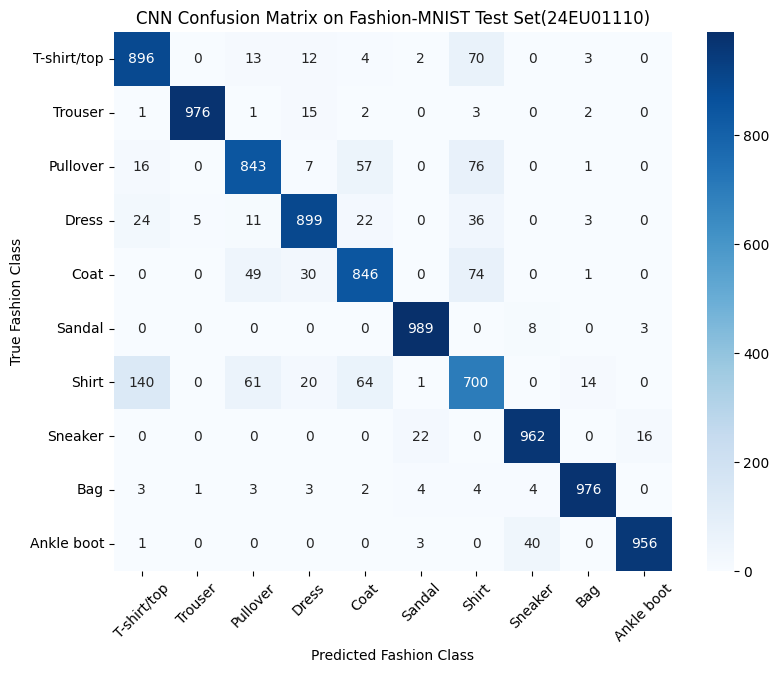

In [5]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Evaluate CNN on test dataset
test_loss, test_acc = cnn_model.evaluate(
    X_test_cnn,
    y_test_cnn,
    verbose=0
)

print(f"CNN Holdout Test Accuracy: {test_acc * 100:.2f}%\n")

# Generate class predictions
y_pred_probs = cnn_model.predict(X_test_cnn)
y_pred_classes = np.argmax(y_pred_probs, axis=1)

# Fashion-MNIST class names
class_names = [
    'T-shirt/top',
    'Trouser',
    'Pullover',
    'Dress',
    'Coat',
    'Sandal',
    'Shirt',
    'Sneaker',
    'Bag',
    'Ankle boot'
]

print("--- Classification Performance Report ---")
print(
    classification_report(
        y_test_raw,
        y_pred_classes,
        target_names=class_names
    )
)

# Generate confusion matrix
cm = confusion_matrix(
    y_test_raw,
    y_pred_classes
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("CNN Confusion Matrix on Fashion-MNIST Test Set(24EU01110)")
plt.xlabel("Predicted Fashion Class")
plt.ylabel("True Fashion Class")
plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.show()

In [6]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt

# Generate cosine wave time-series dataset
t_points = np.linspace(0, 100, 1000)
series_data = np.cos(t_points)

# Create sliding window sequences
def create_sliding_windows(data, lookback=20):
    X, y = [], []

    for i in range(len(data) - lookback):
        X.append(data[i:(i + lookback)])
        y.append(data[i + lookback])

    return np.array(X), np.array(y)

# Lookback window
lookback_steps = 20

X_raw, y_raw = create_sliding_windows(
    series_data,
    lookback_steps
)

# Reshape input for recurrent network
X_seq = np.expand_dims(X_raw, -1)
y_seq = y_raw

# Train-Test Split - 80% training and 20% testing
split_idx = int(0.8 * len(X_seq))

X_train_seq = X_seq[:split_idx]
X_test_seq = X_seq[split_idx:]

y_train_seq = y_seq[:split_idx]
y_test_seq = y_seq[split_idx:]

print("Cosine Wave Sequence Prepared:")
print(f"Training features shape: {X_train_seq.shape}")
print(f"Test features shape: {X_test_seq.shape}")

Cosine Wave Sequence Prepared:
Training features shape: (784, 20, 1)
Test features shape: (196, 20, 1)


### Subtask 2.2: Designing the LSTM Recurrent Neural Network

**Concept:** Construct an LSTM-based recurrent neural network using the Keras Sequential API to learn temporal dependencies from the cosine-wave sequence.

In [7]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM

# Construct LSTM recurrent network
rnn_model = Sequential([

    LSTM(
        50,
        activation='tanh',
        input_shape=(lookback_steps, 1)
    ),

    # Continuous numerical output
    Dense(1)
])

print("LSTM Recurrent Network Architecture established:")
rnn_model.summary()

LSTM Recurrent Network Architecture established:


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,451 (40.82 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

### Subtask 2.3: Compiling and Training the RNN Model

**Concept:** Compile the recurrent model using the Adam optimizer and Mean Squared Error loss, then train it on the prepared cosine-wave sequence dataset.

In [8]:
# Compile recurrent model
rnn_model.compile(
    optimizer='adam',
    loss='mean_squared_error'
)

# Train recurrent model
history_rnn = rnn_model.fit(
    X_train_seq,
    y_train_seq,
    epochs=15,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

print("\nRNN training complete.")

Epoch 1/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - loss: 0.2170 - val_loss: 0.0928
Epoch 2/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0394 - val_loss: 0.0033
Epoch 3/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0032 - val_loss: 0.0012
Epoch 4/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 7.1667e-04 - val_loss: 4.0209e-04
Epoch 5/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 4.0075e-04 - val_loss: 3.2405e-04
Epoch 6/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 3.3175e-04 - val_loss: 2.7558e-04
Epoch 7/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 2.8716e-04 - val_loss: 2.5873e-04
Epoch 8/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 2.5076e-04 - val_loss: 2.5116e-04
Epoch 9/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 2.0943e-04 - val_loss: 1.8374e-04
Epoch 10/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 1.6225e-04 - val_loss: 1.3683e-04
Epoch 11/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.5686e-04 - val_loss: 9.5621e-05

### Subtask 2.4: Visualizing Predicted vs. Actual Sequence Values

**Concept:** Generate predictions using the trained recurrent model and compare the predicted cosine-wave trajectory with the actual test sequence.

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step


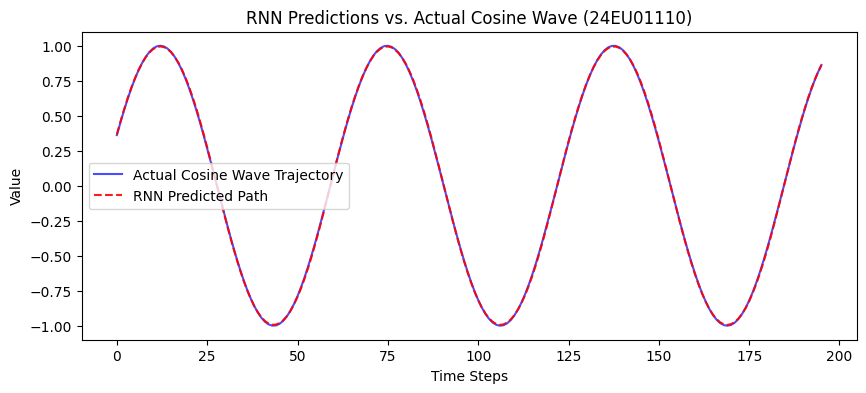

In [9]:
# Predict sequence values
rnn_predictions = rnn_model.predict(
    X_test_seq
)

# Plot actual and predicted trajectories
plt.figure(figsize=(10, 4))

plt.plot(
    y_test_seq,
    label='Actual Cosine Wave Trajectory',
    color='blue',
    alpha=0.7
)

plt.plot(
    rnn_predictions,
    label='RNN Predicted Path',
    color='red',
    linestyle='--',
    alpha=0.9
)

plt.title("RNN Predictions vs. Actual Cosine Wave (24EU01110)")
plt.xlabel("Time Steps")
plt.ylabel("Value")
plt.legend()

plt.show()

### Subtask 2.5: Evaluating Quantitative Sequence Prediction Performance

**Concept:** Calculate MAE, MSE, and R2 Score to quantitatively evaluate the predictive performance of the recurrent model on unseen sequence data.

In [10]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Calculate regression metrics
mae_rnn = mean_absolute_error(
    y_test_seq,
    rnn_predictions
)

mse_rnn = mean_squared_error(
    y_test_seq,
    rnn_predictions
)

r2_rnn = r2_score(
    y_test_seq,
    rnn_predictions
)

print("--- RNN Quantitative Performance ---")
print(f"Mean Absolute Error (MAE): {mae_rnn:.6f}")
print(f"Mean Squared Error (MSE):  {mse_rnn:.6f}")
print(f"Coefficient of Determination (R2): {r2_rnn:.6f}")

--- RNN Quantitative Performance ---
Mean Absolute Error (MAE): 0.004673
Mean Squared Error (MSE):  0.000029
Coefficient of Determination (R2): 0.999941
